# Diabetes Prediction using Logistic Regression

**Goal:** Predict whether a person has diabetes (`Outcome` = 1) or not (`Outcome` = 0) from diagnostic measurements.

**Dataset:** `diabetes.csv` (768 rows, 8 features + target; Pima Indians Diabetes data).

**Workflow:** load data → clean → explore → split → scale → train → evaluate → tune → predict on new patient.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the data

In [2]:
FILE = "diabetes.csv"   # change the path if the file is elsewhere

df = pd.read_csv(FILE)
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
print()
print("Missing values (NaN):\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values (NaN):
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age              

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 2. Data cleaning

Columns like `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` **cannot be 0** for a living person. The zeros here are really *missing values*. Leaving them as 0 would distort the model, so we convert them to `NaN` and impute later (median, inside the pipeline so there is no data leakage).

In [4]:
zero_invalid = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zeros per column (before):")
print((df[zero_invalid] == 0).sum())

df[zero_invalid] = df[zero_invalid].replace(0, np.nan)

print("\nMissing % after conversion:")
print((df[zero_invalid].isna().mean() * 100).round(1))

Zeros per column (before):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing % after conversion:
Glucose           0.7
BloodPressure     4.6
SkinThickness    29.6
Insulin          48.7
BMI               1.4
dtype: float64


## 3. Exploratory data analysis

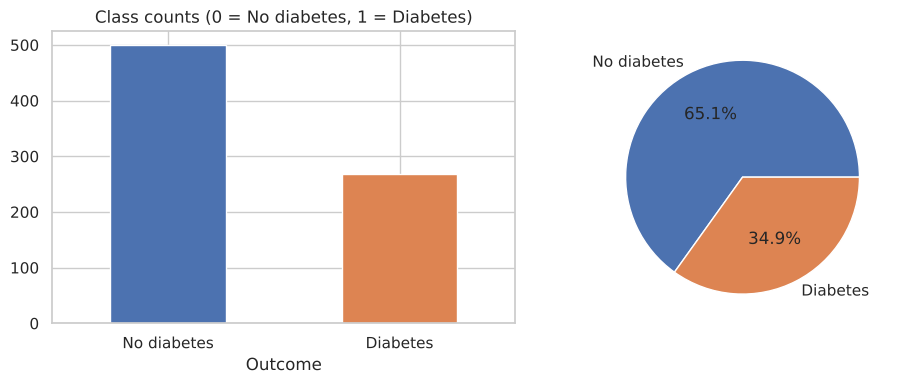

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df["Outcome"].value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Class counts (0 = No diabetes, 1 = Diabetes)")
ax[0].set_xticklabels(["No diabetes", "Diabetes"], rotation=0)
df["Outcome"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[1],
                                  labels=["No diabetes", "Diabetes"], colors=["#4C72B0", "#DD8452"])
ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

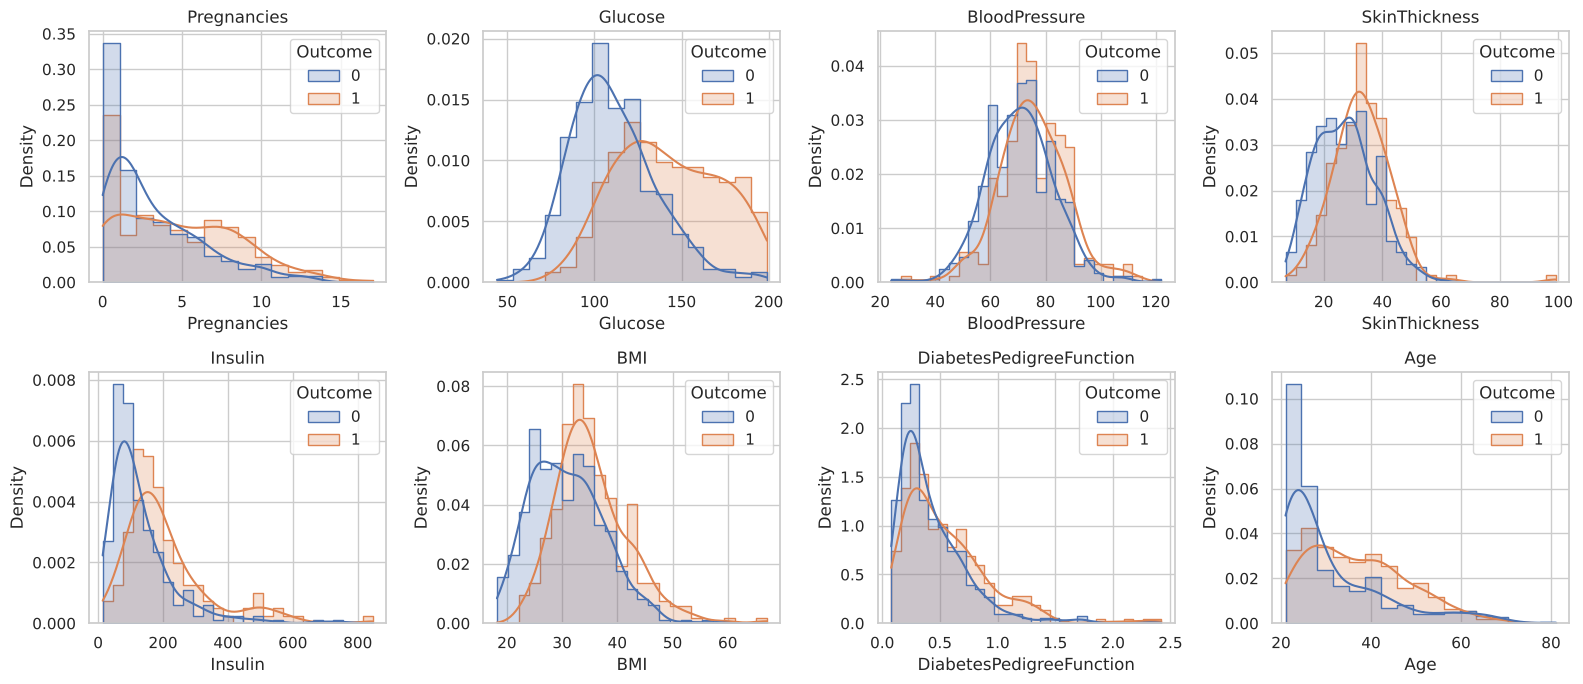

In [6]:
features = df.drop(columns="Outcome").columns
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for a, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=a, element="step", stat="density", common_norm=False)
    a.set_title(col)
plt.tight_layout(); plt.show()

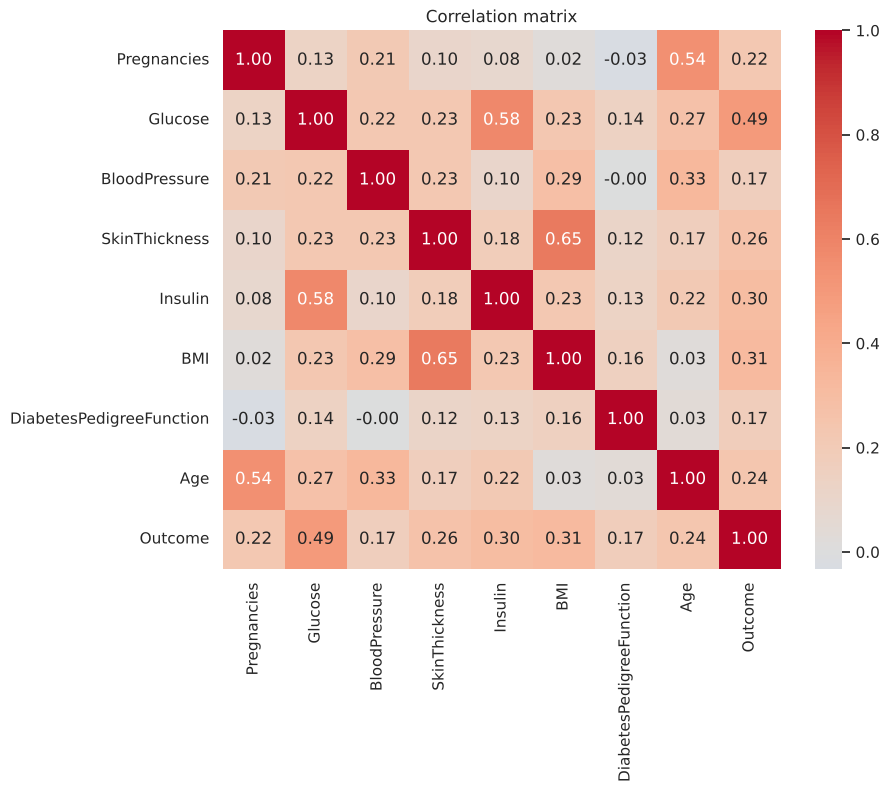

Correlation with Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print("Correlation with Outcome:")
print(df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

## 4. Train / test split

A stratified split keeps the diabetic / non-diabetic ratio the same in both sets (the data is imbalanced, ~65% / 35%).

In [8]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), " Test class ratio:", y_test.mean().round(3))

Train: (614, 8)  Test: (154, 8)
Train class ratio: 0.349  Test class ratio: 0.351


## 5. Baseline logistic regression

Pipeline = **median imputation → standard scaling → logistic regression**. Putting everything in a pipeline means the imputer and scaler are fitted on training data only, so no information leaks from the test set.

In [9]:
base_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
base_model.fit(X_train, y_train)

y_pred = base_model.predict(X_test)
y_prob = base_model.predict_proba(X_test)[:, 1]

def report(name, y_true, y_pred, y_prob):
    print(f"--- {name} ---")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred):.3f}")
    print(f"Recall   : {recall_score(y_true, y_pred):.3f}")
    print(f"F1-score : {f1_score(y_true, y_pred):.3f}")
    print(f"ROC-AUC  : {roc_auc_score(y_true, y_prob):.3f}")

report("Baseline Logistic Regression", y_test, y_pred, y_prob)
print()
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"]))

--- Baseline Logistic Regression ---
Accuracy : 0.708
Precision: 0.600
Recall   : 0.500
F1-score : 0.545
ROC-AUC  : 0.813

              precision    recall  f1-score   support

 No diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



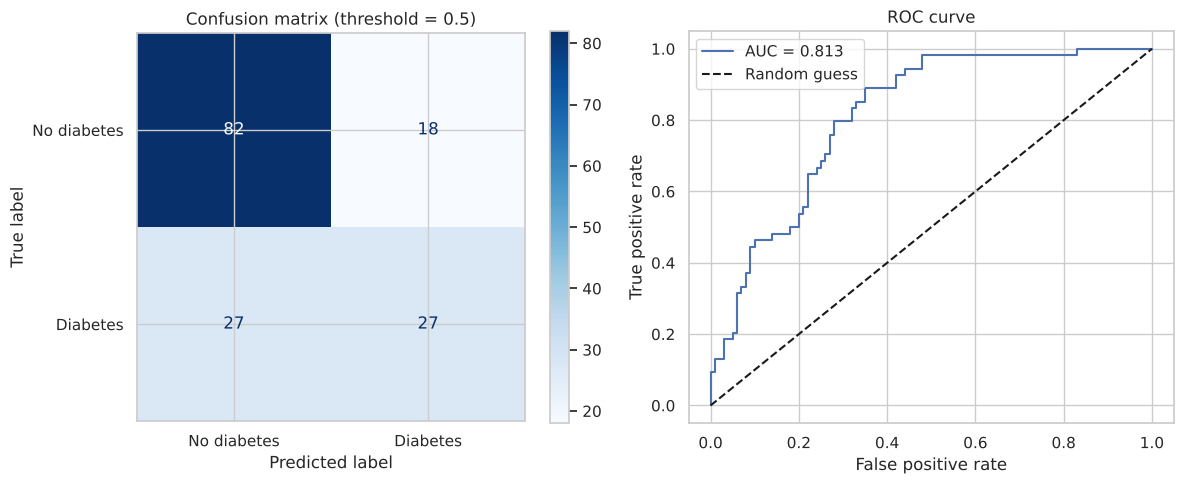

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No diabetes", "Diabetes"],
                                        cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion matrix (threshold = 0.5)")

fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
ax[1].plot([0, 1], [0, 1], "k--", label="Random guess")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Cross-validation

A single 80/20 split on 768 rows is noisy. 5-fold stratified cross-validation gives a more trustworthy estimate of performance.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for metric in ["accuracy", "recall", "roc_auc"]:
    scores = cross_val_score(base_model, X, y, cv=cv, scoring=metric)
    print(f"{metric:9s}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy : 0.772 ± 0.017
recall   : 0.571 ± 0.047
roc_auc  : 0.837 ± 0.020


## 7. Hyperparameter tuning

We tune the regularization strength `C` and the penalty. We also try `class_weight="balanced"`, which penalizes missing a diabetic patient more heavily. We optimise **ROC-AUC** because accuracy alone is misleading on imbalanced data.

In [12]:
param_grid = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["liblinear"],
    "clf__class_weight": [None, "balanced"],
}
grid = GridSearchCV(base_model, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print("Best CV AUC :", round(grid.best_score_, 3))

best_model = grid.best_estimator_
y_pred_t = best_model.predict(X_test)
y_prob_t = best_model.predict_proba(X_test)[:, 1]
report("Tuned Logistic Regression", y_test, y_pred_t, y_prob_t)

Best params : {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Best CV AUC : 0.845
--- Tuned Logistic Regression ---
Accuracy : 0.721
Precision: 0.585
Recall   : 0.704
F1-score : 0.639
ROC-AUC  : 0.811


## 8. Choosing a decision threshold

For medical screening, **missing a diabetic patient (false negative) is usually worse than a false alarm**. The default threshold of 0.5 isn't sacred. Below is the precision/recall trade-off at different thresholds, evaluated on the test set for illustration. In a real project, pick the threshold on a validation set, not the test set.

In [13]:
rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]:
    p = (y_prob_t >= t).astype(int)
    rows.append({"threshold": t,
                 "accuracy": accuracy_score(y_test, p),
                 "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p),
                 "f1": f1_score(y_test, p)})
pd.DataFrame(rows).round(3)

,threshold,accuracy,precision,recall,f1
0,0.30,0.695,0.539,0.889,0.671
1,0.35,0.701,0.545,0.889,0.676
2,0.40,0.721,0.570,0.833,0.677
3,0.45,0.727,0.579,0.815,0.677
4,0.50,0.721,0.585,0.704,0.639
5,0.55,0.734,0.614,0.648,0.631
6,0.60,0.714,0.593,0.593,0.593


## 9. Feature importance (coefficients)

Features were standardized, so coefficient sizes are directly comparable. Positive = raises diabetes risk, negative = lowers it. `exp(coef)` is the odds ratio per 1 standard deviation increase.

,feature,coefficient,odds_ratio
1,Glucose,1.022,2.778
5,BMI,0.597,1.817
0,Pregnancies,0.320,1.377
6,DiabetesPedigreeFunction,0.255,1.291
7,Age,0.188,1.206
3,SkinThickness,0.057,1.059
2,BloodPressure,0.017,1.018
4,Insulin,0.016,1.017


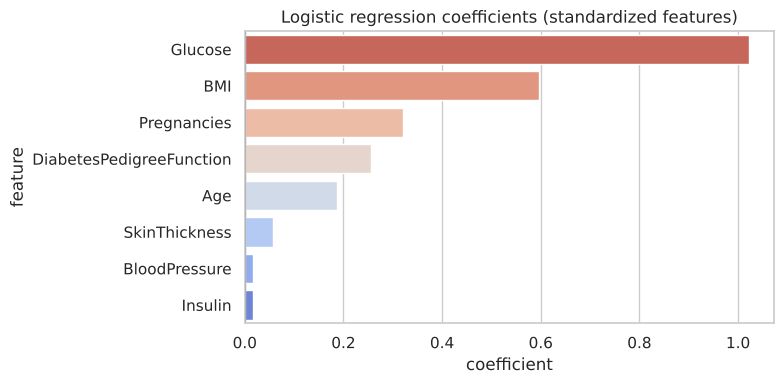

In [14]:
coefs = pd.DataFrame({
    "feature": X.columns,
    "coefficient": best_model.named_steps["clf"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coefficient"])
coefs = coefs.sort_values("coefficient", ascending=False)
display(coefs.round(3))

plt.figure(figsize=(8, 4))
sns.barplot(data=coefs, x="coefficient", y="feature", palette="coolwarm_r")
plt.axvline(0, color="k", lw=0.8)
plt.title("Logistic regression coefficients (standardized features)")
plt.tight_layout(); plt.show()

## 10. Predict for a new person

In [15]:
new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 150,
    "BloodPressure": 85,
    "SkinThickness": 30,
    "Insulin": 120,
    "BMI": 33.5,
    "DiabetesPedigreeFunction": 0.55,
    "Age": 45,
}])

prob = best_model.predict_proba(new_patient)[0, 1]
label = best_model.predict(new_patient)[0]
print(f"Probability of diabetes: {prob:.1%}")
print("Prediction:", "Diabetic" if label == 1 else "Not diabetic")

Probability of diabetes: 71.6%
Prediction: Diabetic


## 11. Save the model (optional)

In [16]:
import joblib
joblib.dump(best_model, "diabetes_logreg_model.pkl")
# Reload later with: model = joblib.load("diabetes_logreg_model.pkl")

['diabetes_logreg_model.pkl']

## Summary & limitations

- Results in this run: 5-fold CV accuracy ≈ **77%**, ROC-AUC ≈ **0.84**. On the single 80/20 test split accuracy was lower (≈ 71-72%, AUC ≈ 0.81): with only 154 test rows, one split is noisy, so trust the CV numbers more.
- At the default 0.5 threshold the baseline **recall for diabetics is only ~50%** — it misses about half of true cases. `class_weight="balanced"` lifts recall to ~70% at the cost of precision. Accuracy alone hides this.
- **Glucose, BMI, Age and DiabetesPedigreeFunction** are typically the strongest predictors.
- The dataset is small (768 rows) and comes from one population (Pima Indian women aged 21+), so the model **should not be used for real medical decisions** and may not generalize to other groups.
- Possible improvements: feature engineering (e.g. BMI categories, age bins), more flexible models (Random Forest, XGBoost) for comparison, and more data.